# Step 11: a fresh exam on a second fire

**Why:** fix C (look-alikes by score *and* height) was designed after seeing Black Cove's mistakes. Grading it on Black Cove is like grading a student on a test they already saw. So here the whole recipe runs, unchanged, on a fire it has never seen.

**The fire:** Great Lakes, Croatan National Forest, eastern North Carolina, April 2023. About 130 km², on flat, swampy coastal ground.

**Rules fixed before looking at any burn pixel**
- **Answer key:** the fire agencies' certified final outline (NIFC). The other outline for this fire (MTBS) is drawn from the same kind of satellite score we are testing, so it would be a weaker judge.
- **Photo pairs,** one satellite each: Landsat April 18 to May 4, and Sentinel-2 April 10 to May 10.
- **Maps:** the same five, nothing retuned: textbook cutoff, histogram cutoff, fix A, fix B, fix C.

**Predictions written down first**
1. Flat ground, so height should not matter: fix C about equal to fix A.
2. Mostly evergreen plants, so little leaf-season shift: the plain cutoffs should work.

In [1]:
import sys, importlib
from pathlib import Path
sys.path.insert(0, str(Path('..') / 'src'))
import numpy as np
import pandas as pd
import hls, fires
step11 = importlib.import_module('11_second_fire')  # reuse the script's functions
step7 = step11.step7
# The script saves pictures to files only. This line also shows them here in the notebook.
%matplotlib inline
hls.login();

## Two outlines for the same fire
How much do the fire crews' outline (NIFC) and the satellite archive's outline (MTBS) agree?

In [2]:
nifc = fires.outline(step11.FIRE)
mtbs = fires.outline('Great Lakes (Apr 2023)')
print(f"NIFC outline: {fires.area_km2(nifc):.1f} km2 = {fires.area_km2(nifc) * fires.ACRES_PER_KM2:,.0f} acres")
print(f"MTBS outline: {fires.area_km2(mtbs):.1f} km2")
print(f"In both: {fires.area_km2(nifc.intersection(mtbs)):.1f} km2. NIFC only: {fires.area_km2(nifc.difference(mtbs)):.1f}. MTBS only: {fires.area_km2(mtbs.difference(nifc)):.1f}.")

NIFC outline: 130.1 km2 = 32,156 acres
MTBS outline: 125.6 km2
In both: 124.6 km2. NIFC only: 5.5. MTBS only: 0.9.


## First look
Same false-color picture as Step 7: burned ground looks red-brown.

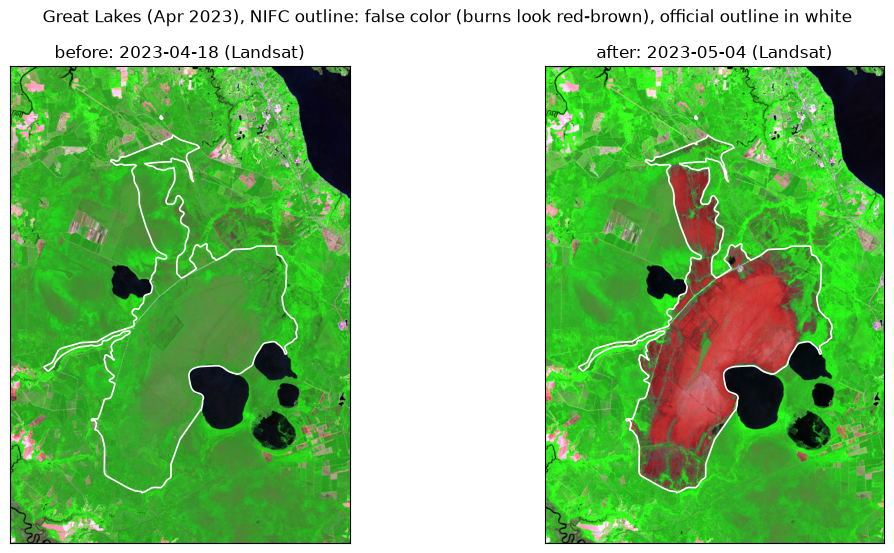

In [3]:
p = step11.PAIRS['Landsat']
step7.plot_first_look(step11.FIRE, p['before'], p['after'], 'Landsat', '../figures/11_great_lakes_first_look.png');

The scar is far stronger than Black Cove's. This fire burned through the plants themselves, not just the leaf litter under bare trees.

Notice the green strips *inside* the white outline, along the top-right rim. An outline is drawn around a fire; it does not promise everything inside burned.

## Run the unchanged recipe

In [4]:
r = step11.run()
print(f"Outline = {r['inside'].mean():.0%} of the box. Ground height: "
      f"{np.nanpercentile(r['height'], 1):.0f} to {np.nanpercentile(r['height'], 99):.0f} m (middle 98% of pixels)")
r['facts'].set_index('pair').T

Outline = 19% of the box. Ground height: 0 to 24 m (middle 98% of pixels)


pair,Landsat,Sentinel-2
box usable,92%,91%
outline visible,99%,100%
"median change, whole box",-0.036,-0.071
top of the pile,-0.035,-0.075
histogram cutoff,0.055,0.055
normal change in the ring,-0.048,-0.096
"look-alike groups, lowest",-0.061,-0.128
"look-alike groups, highest",0.036,-0.016
fix A groups: most-burned group,50%,42%
fix A groups: groups over half burned,1 of 20,0 of 20


In [5]:
r['scores']

,pair,map,flagged km2,caught,right,F1,false alarms km2,overall accuracy
0,Landsat,textbook,108.7,0.832,0.984,0.902,1.7,0.963
1,Landsat,histogram,113.2,0.853,0.969,0.907,3.5,0.964
2,Landsat,fix A: look-alikes,112.2,0.849,0.972,0.906,3.1,0.964
3,Landsat,fix B: ring,113.7,0.854,0.967,0.907,3.8,0.964
4,Landsat,fix C: look-alikes + height,105.2,0.790,0.965,0.869,3.6,0.951
5,Sentinel-2,textbook,111.3,0.823,0.959,0.886,4.6,0.956
6,Sentinel-2,histogram,117.3,0.842,0.930,0.884,8.2,0.954
7,Sentinel-2,fix A: look-alikes,130.8,0.857,0.848,0.852,19.9,0.938
8,Sentinel-2,fix B: ring,133.6,0.870,0.844,0.856,20.9,0.939
9,Sentinel-2,fix C: look-alikes + height,127.5,0.819,0.832,0.825,21.4,0.928


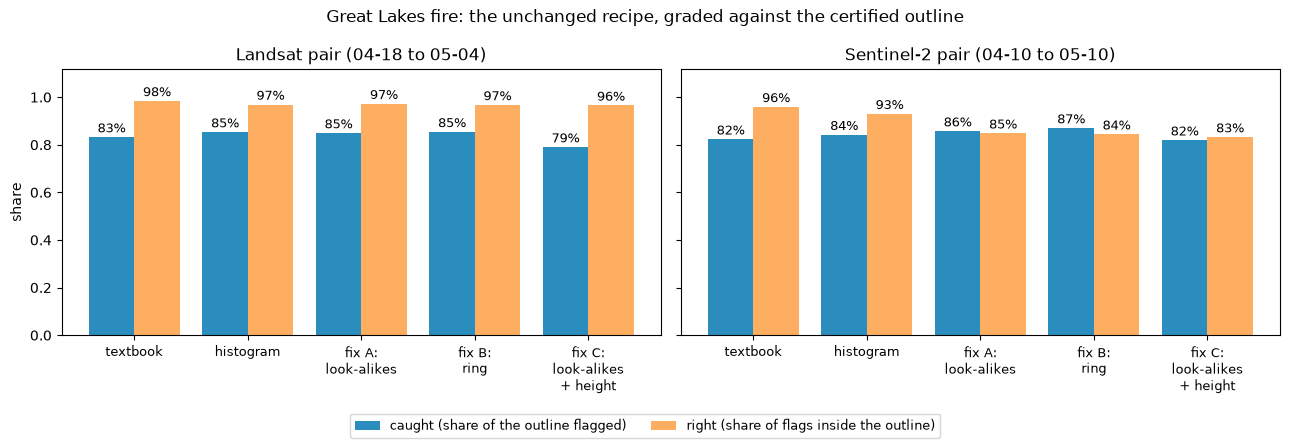

In [6]:
step11.plot_scores(r['scores'], '../figures/11_great_lakes_scores.png');

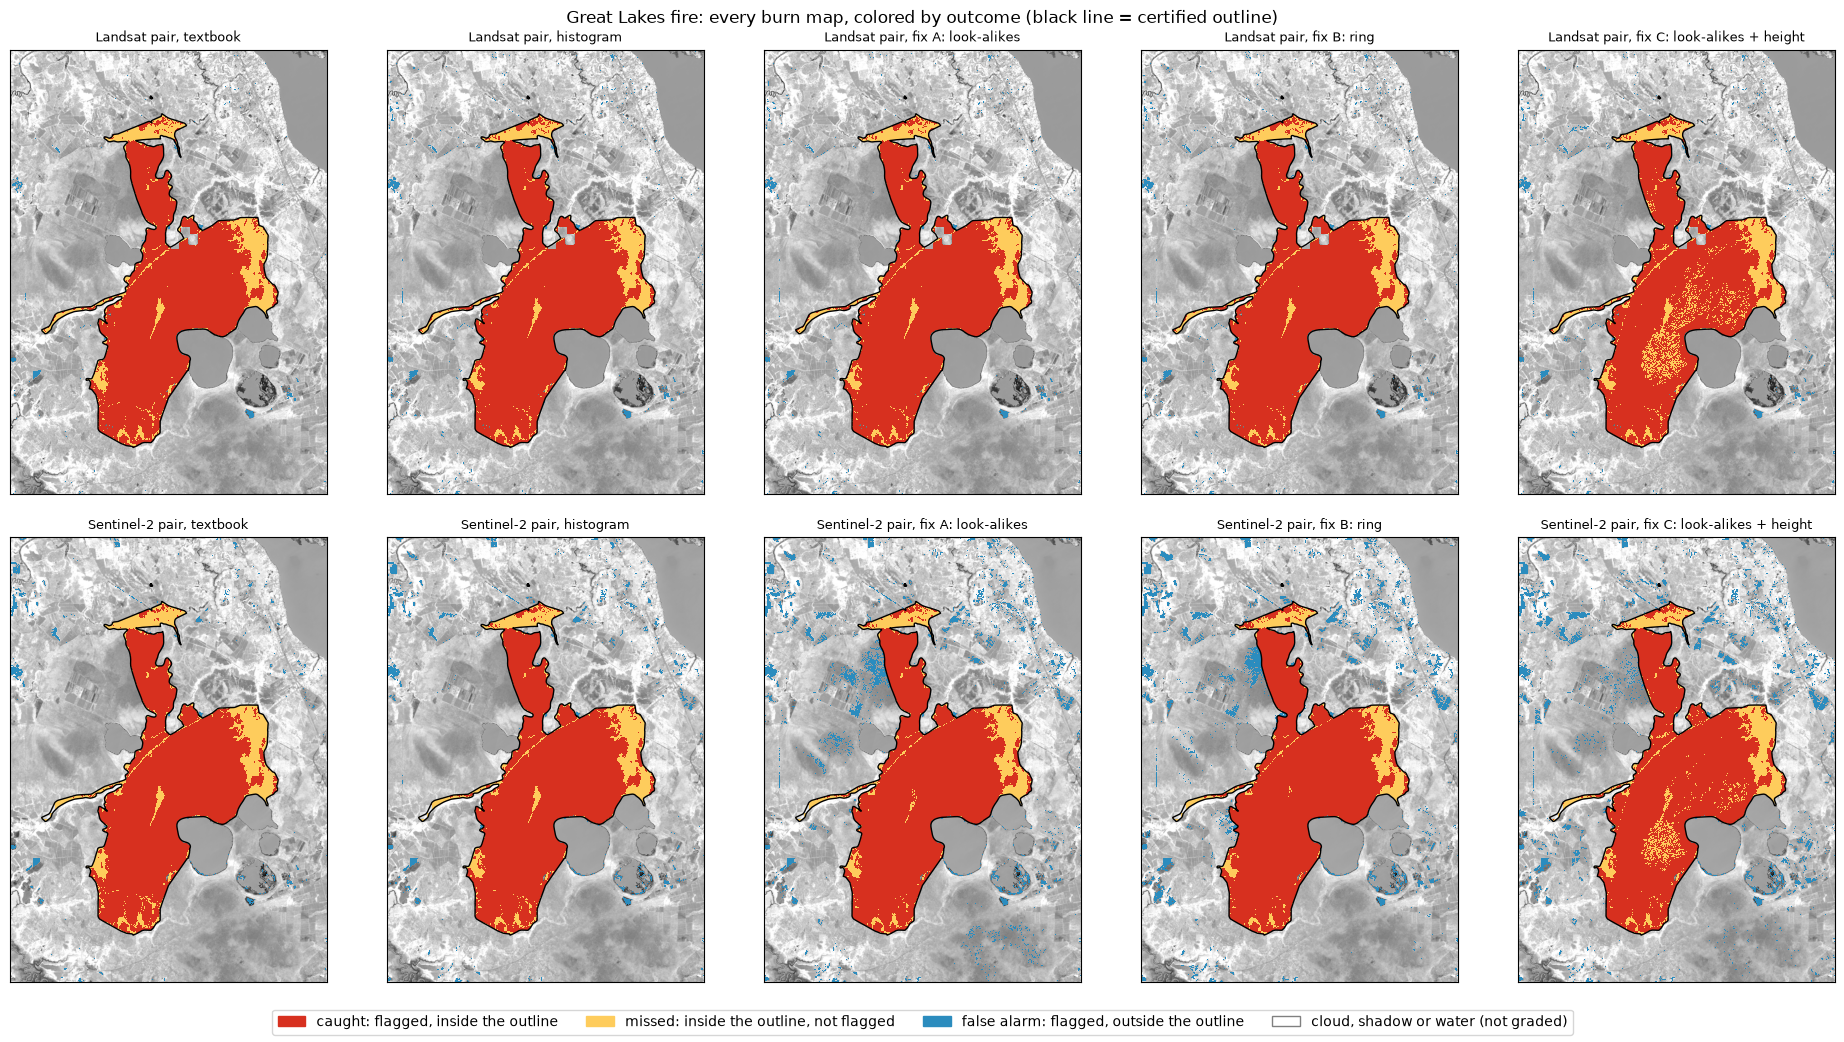

In [7]:
step11.plot_outcomes(r, '../figures/11_great_lakes_outcomes.png');

## Both fires side by side

In [8]:
step11.both_fires(r['scores'])

,fire,pair,map,caught,right,F1
0,Black Cove,April,textbook,0.157,0.993,0.272
1,Black Cove,April,histogram,0.262,0.939,0.409
2,Black Cove,April,fix A: look-alikes,0.422,0.257,0.320
3,Black Cove,April,fix B: ring,0.366,0.325,0.344
4,Black Cove,April,fix C: look-alikes + height,0.522,0.484,0.502
5,Black Cove,March 26,textbook,0.613,0.958,0.747
6,Black Cove,March 26,histogram,0.728,0.839,0.779
7,Black Cove,March 26,fix A: look-alikes,0.646,0.944,0.767
8,Black Cove,March 26,fix B: ring,0.641,0.945,0.764
9,Black Cove,March 26,fix C: look-alikes + height,0.644,0.944,0.766


The same table as one picture. Each bar is one map's F1: one number that is only high when "caught" and "right" are both high.

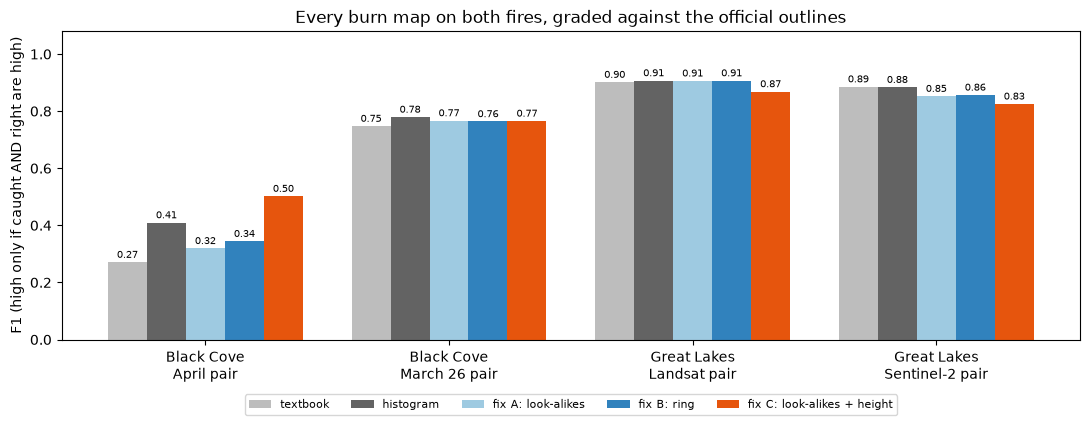

In [9]:
step11.plot_both_fires(step11.both_fires(r['scores']), '../figures/11_both_fires.png');

## What we learned
- **The simple method passed the fresh exam.** With no retuning, the textbook cutoff caught 83% of the outline and was right 98% of the time (Landsat pair). That is far better than on Black Cove.
- **Prediction 2 was right.** In the Landsat pair unburned land barely moved (-0.04), so there was nothing to correct.
- **Prediction 1 was only half right.** Fix C did not match fix A; it was a little *worse* (caught 79% vs 85%). Height carried no information here (the whole box is within about 24 m), and splitting into more groups hurt.
- **Why it hurt, measured:** this burn is so large that one of fix C's 50 groups is 65% burned. "Normal" is the middle value of a group. When most of a group burned, its middle value is a burned pixel, so burned starts to look normal. On Black Cove the worst group was only 30% burned.
- **The fixes cost accuracy when there is little to fix.** In the Sentinel-2 pair, fixes A, B and C all added false alarms (about 20 km², against 5 for the textbook cutoff).
- **So fix C does not generalize as "always better".** It helped on one fire, where height drove the leaf season, and slightly hurt on another.

## The honest summary of the burn phase
- A plain before-minus-after map from **two photos close together in time** was the best map on both fires.
- Corrections for the leaf season only pay off when the season really moved between the photos, and they bring their own mistakes.
- Many of the "missed" pixels here look unburned in the photo, so "caught" understates the maps.

## Limits
- **Two fires.** Better than one, still a small sample.
- **A bug the second fire found:** my cutoff helper assumed the change in score never exceeds 1. This fire's most severe pixels do, and the helper crashed. Fixed; Black Cove's numbers did not change.
- **The two outlines agree closely** (124.6 km² in common), so they may share some source. I could not check how the fire crews drew theirs beyond "mixed methods".